# Week 2 Assignment | Regularization


Task:

Your task is to build a fully connected neural network model for predicting the median house value in California districts, using the available features in the dataset. You should start by first building a large enough model that you can recognize to overfit the training data. After this, you should try out different strategies for reducing overfitting, and select the one that leads to the best results on the validation set - in terms of mean absolute error (MAE).

Prepare a Jupyter notebook containing an account of the problem treatment. You do not have to report all the different experiments and their results (training printouts etc.) in detail: a short mention of the various trials is enough. However, the training and subsequent testing of the finally selected model must be presented in the notebook.

Note the following:

- You should use three separate datasets: training, validation, and test sets.

- First, try out a few different model architectures (without any regularization) until you find one that clearly overfits the training data.

- Try out some of the strategies for reducing overfitting, and pick the ones leading to the most promising results on the validation set.

- Train the final model once more with training and validation sets combined, and evaluate it with the test set.

- Use markdown cells to document your work.


In [31]:
import keras
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.datasets import california_housing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [45]:
def plot_loss(history):
    plt.plot(history.history['loss'][10:], label='Training Loss')
    plt.plot(history.history['val_loss'][10:], label='Validation Loss')
    plt.legend()
    plt.xlabel('Epochs')
    plt.ylabel('Loss')

## Data

For this assignment I'm using a California housing dataset https://keras.io/api/datasets/california_housing/

In [32]:
(inputs, targets), (x_test, y_test) = california_housing.load_data(
    version="large", path="california_housing.npz", test_split=0.2, seed=113
)

print(f"Inputs shape: {inputs.shape}")
print(f"Targets shape: {targets.shape}")
print(f"Test inputs shape: {x_test.shape}")
print(f"Test targets shape: {y_test.shape}")

Inputs shape: (16512, 8)
Targets shape: (16512,)
Test inputs shape: (4128, 8)
Test targets shape: (4128,)


In [33]:
# Split the data into training and validation sets

x_train = inputs[:15000]
y_train = targets[:15000]
x_val = inputs[15000:]
y_val = targets[15000:]

In [34]:
# Standardize the input features by substracting the mean and dividing by the standard deviation

mean = x_train.mean(axis=0)
std = x_train.std(axis=0)
x_train -= mean
x_train /= std
x_test -= mean
x_test /= std
x_val -= mean
x_val /= std

# Rescale the target values by dividing by 1e5 to make them more manageable for the model
y_train /= 1e5
y_test /= 1e5
y_val /= 1e5

## Baseline Model

In [64]:
model = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [65]:
# Training

history = model.fit(x_train, y_train, epochs=500, batch_size=32, validation_data=(x_val, y_val), verbose=0)

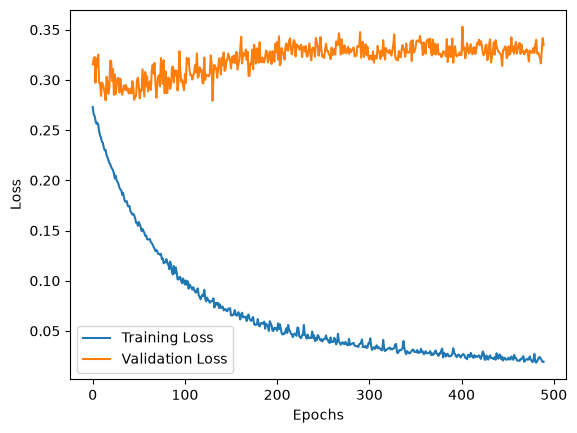

In [66]:
plot_loss(history)

The validation loss starts increasing at about 50 epochs which indicates model overfitting.

### Regularization

I will try 4 different methods to reduce overfitting and compare which offers the best results:
- L2 Regularization
- Dropout
- Batch normalization
- Early stopping

#### L2 Regularization

In [38]:
from keras.regularizers import l2

model_l2 = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(256, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(1)
])

model_l2.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [39]:
history_l2 = model_l2.fit(x_train, y_train, epochs=500, batch_size=32, validation_data=(x_val, y_val), verbose=0)

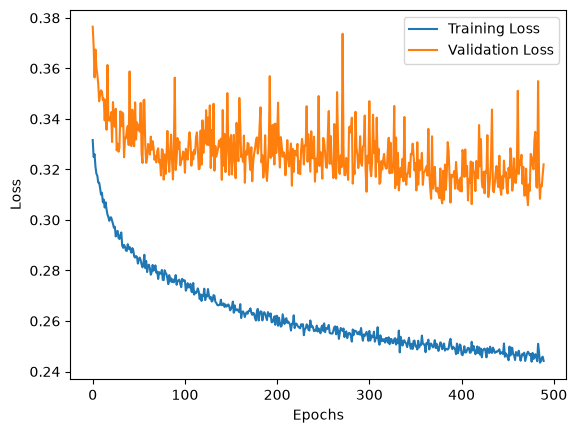

In [47]:
plot_loss(history_l2)


L2 Regularization reduced overfitting but the validation loss has a lot of variance.

#### Dropout

In [41]:
from keras.layers import Dropout

model_do = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(1)
])

model_do.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [42]:
history_do = model_do.fit(x_train, y_train, epochs=500, batch_size=32, validation_data=(x_val, y_val), verbose=0)

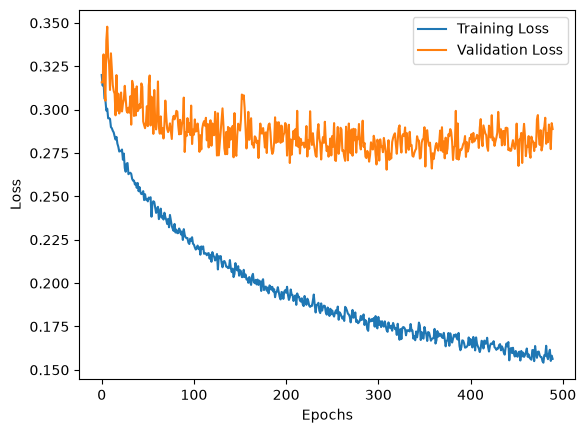

In [48]:
plot_loss(history_do)

This plot shows that the overfitting has reduced significantly and doesn't show clear signs of overfitting.

#### Batch normalization

In [49]:
from keras.layers import BatchNormalization

model_bn = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dense(1)
])

model_bn.compile(optimizer='adam', loss='mse', metrics=['mae'])

In [50]:
history_bn = model_bn.fit(x_train, y_train, epochs=500, batch_size=32, validation_data=(x_val, y_val), verbose=0)

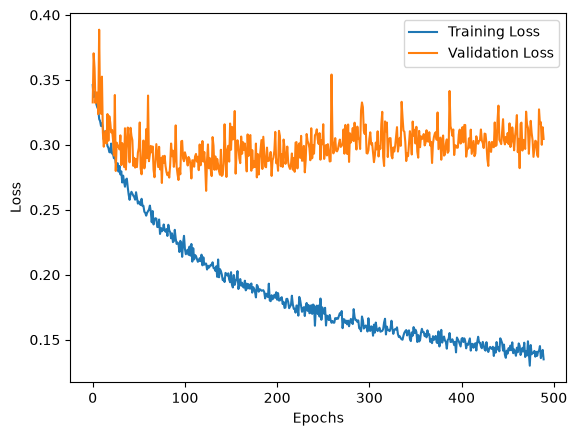

In [51]:
plot_loss(history_bn)

Batch normalization was able to reduce overfitting but shows a small increase of validation loss after 100 epochs.

#### Early stopping

In [60]:
from keras.callbacks import EarlyStopping

model_es = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(256, activation='relu'),
    Dense(1)
])

model_es.compile(optimizer='adam', loss='mse', metrics=['mae'])

early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [61]:
history_es = model_es.fit(x_train, y_train, epochs=500, batch_size=32, validation_data=(x_val, y_val), verbose=0, callbacks=[early_stopping])

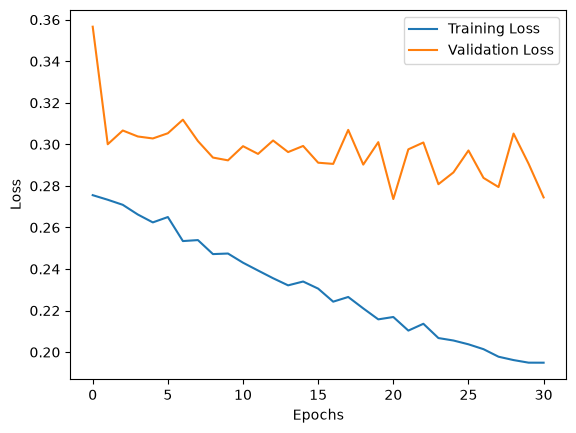

In [62]:
plot_loss(history_es)

Early stopping terminated the training at about 40 epochs.

### Comparing

In [67]:
histories = {
    'Baseline': history,
    'L2': history_l2,
    'Dropout': history_do,
    'Batch norm': history_bn,
    'Early stopping': history_es,
}

rows = []
for name, h in histories.items():
    val_mae = np.array(h.history['val_mae'])
    best = val_mae.argmin()
    rows.append({
        'Model': name,
        'Best val MAE': val_mae[best],
        'Best epoch': best + 1,
        'Final val MAE': val_mae[-1],
        'Epochs trained': len(val_mae),
    })

results = pd.DataFrame(rows).set_index('Model')
results['Best val MAE ($)'] = (results['Best val MAE'] * 1e5).round(-2)
results

,Best val MAE,Best epoch,Final val MAE,Epochs trained,Best val MAE ($)
Model,,,,,
Baseline,0.335903,58,0.366389,500,33600.0
L2,0.334539,460,0.344851,500,33500.0
Dropout,0.321636,396,0.345669,500,32200.0
Batch norm,0.332769,86,0.370819,500,33300.0
Early stopping,0.335764,34,0.341496,41,33600.0


I chose dropout for the final model as it gave the best results.

- Dropout has the lowest validation MAE: 0.322 and about $32k
- Validation curve stays flat and shows no signs of rising while in the baseline model without regularization the curve had risen a lot 
- The validation curve had the least visible noise compared to the other methods


## Final Model

For the final model I will combine the training and validation sets

In [69]:
x_train_full = np.concatenate((x_train, x_val), axis=0)
y_train_full = np.concatenate((y_train, y_val), axis=0)

In [75]:
final_model = Sequential([
    Input(shape=(8,)),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(256, activation='relu'),
    Dropout(0.2),
    Dense(1)
])

final_model.compile(optimizer='adam', loss='mse', metrics=['mae'])
final_history = final_model.fit(x_train_full, y_train_full, epochs=500, batch_size=32, verbose=0)

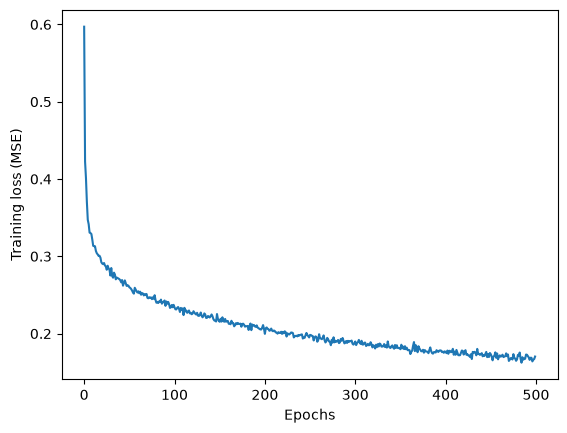

In [80]:
plt.plot(final_history.history['loss'])
plt.xlabel('Epochs'); plt.ylabel('Training loss (MSE)')
plt.show()

### Testing

In [77]:
test_loss, test_mae = final_model.evaluate(x_test, y_test)
print(f"Test loss: {test_loss:.4f}, Test MAE: {test_mae:.4f}")

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.2728 - mae: 0.3454
Test loss: 0.2728, Test MAE: 0.3454


Conclusion:

- The final model's test MAE is 0.345 and doesnt differ much from the baseline model's validation MAE.
- Early stopping was not needed because the validation curve did not rise during 500 epochs.